In [3]:

import pandas as pd
import numpy as np
from Bio.Data import CodonTable
from Bio import SeqIO
from Bio.Seq import Seq
from Bio.SeqUtils import seq3
import random
from Bio.SeqUtils import GC123
import multiprocessing as mp

import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
import matplotlib.font_manager

from pathlib import Path

import matplotlib as mpl

from matplotlib.patches import Patch
from matplotlib.lines import Line2D



fpath = Path(mpl.get_data_path(), "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")

from matplotlib.font_manager import FontProperties
from matplotlib import font_manager

font_path = "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf"
font_manager.fontManager.addfont("/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")
prop = font_manager.FontProperties(fname=font_path)
plt.rcParams['figure.dpi'] = 300
plt.rcParams['svg.fonttype']='none'


## Run deeploc  to obtain subcellular localization predictions

In [2]:
!mkdir "$SCRATCH/extavour_lab/Everyone/Rishabh/split_fastas"

In [21]:
!mkdir /n/netscratch/extavour_lab/Everyone/Rishabh/deeploc_results

In [5]:
input_file = open(f"ncbi_dataset/data/GCF_014529535.2/longest_isoform.fasta")
fasta = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))

In [132]:
!mkdir "/n/netscratch/extavour_lab/Everyone/Rishabh/split_fastas"

In [12]:
##split fasta of all bcoprop longest protien isoforms to subfastas of size 10 to run deeploc in parallel
n=0
i=0
for x in fasta:
   
    if i%10==0:
        n+=1
    f=open(f"/n/netscratch/extavour_lab/Everyone/Rishabh/split_fastas/{n}.fasta","a")
    f.write(f">{x}"+"\n")
    f.write(str(fasta[x].seq)+"\n")
    f.close()
    i+=1

In [21]:
!sbatch scripts/deep.sh

Submitted batch job 29164376


In [28]:
##concatenate deeploc results
# List to store dataframes
dfs = []
import os
# Iterate over each file in the directory
for x in os.listdir("/n/netscratch/extavour_lab/Everyone/Rishabh/deeploc_results"):
    # for filename in os.listdir(f"deeploc_results/{x}"):
    if '.csv' in x:
        # Read CSV file into a dataframe
        df = pd.read_csv(f"/n/netscratch/extavour_lab/Everyone/Rishabh/deeploc_results/{x}")
        # Append dataframe to the list
        dfs.append(df)

# Concatenate all dataframes in the list
result = pd.concat(dfs, ignore_index=True)
result=result.set_index('Protein_ID')
result.to_csv("outputs/deeploc_results.csv")

In [1]:
from collections import Counter

In [4]:
dfriso=pd.read_csv("outputs/per_protein_diamond_data.tsv",sep="\t",index_col="accession")
hgts=set(dfriso[dfriso.tree_HTG].index)

In [14]:
result=pd.read_csv("outputs/deeploc_results.csv",index_col=0)

In [27]:
tr=set(fasta.keys())-set(result.index)
for x in tr:
    f=open(f"/n/netscratch/extavour_lab/Everyone/Rishabh/split_fastas/{x}","a")
    f.write(f">{x}"+"\n")
    f.write(str(fasta[x].seq)+"\n")
    f.close()

In [26]:
tr=set(fasta.keys())-set(result.index)
for x in tr:
    !sbatch scripts/deeplocsh.sh "$x"

Submitted batch job 29228355
Submitted batch job 29228363
Submitted batch job 29228373
Submitted batch job 29228378
Submitted batch job 29228381


In [31]:
result.loc[list(hgts),:].to_csv("outputs/hgt_deeploc_results.csv")

In [5]:
locs=["Cytoplasm","Nucleus","Extracellular","Mitochondrion", "Cell membrane","Lysosome/Vacuole","Golgi apparatus","Endoplasmic reticulum","Peroxisome"]

In [15]:
locdf=pd.DataFrame(index=locs,columns=["HGT","Not-HGT"])
locdf=locdf.fillna(0)

/tmp/ipykernel_3155589/114894112.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  locdf=locdf.fillna(0)


In [16]:
for index, row in result.iterrows():
    locsi=row.Localizations.split("|")
   
    for l in locsi:
        if l in locs:
            if index in hgts:
                locdf.loc[l,"HGT"]+=1
            else:
                locdf.loc[l,"Not-HGT"]+=1

In [17]:

locdf.loc[:,"p_HGT"]=locdf.loc[:,"HGT"]/locdf.loc[:,"HGT"].sum()
locdf.loc[:,"p_Not-HGT"]=locdf.loc[:,"Not-HGT"]/locdf.loc[:,"Not-HGT"].sum()

In [19]:
from scipy.stats import fisher_exact
import numpy as np

def go_enrichment_analysis(go_counts, background_counts,alternative='two-sided'):
    """
    Perform GO term enrichment analysis using Fisher's exact test.

    Args:
    go_counts (list): A list containing counts for the GO term.
    background_counts (list): A list containing counts for the background set.

    Returns:
    tuple: A tuple containing enrichment fold change and p-value.
    """
    # Check if counts contain at least two elements
    if len(go_counts) != 2 or len(background_counts) != 2:
        raise ValueError("Counts must contain exactly two elements.")

    # Perform Fisher's exact test to compute p-value
    odds_ratio, p_value = fisher_exact([go_counts, background_counts],alternative=alternative)

    # Compute fold change
    fold_change = ((go_counts[0]+1) /(np.sum(go_counts)+1)) / ((background_counts[0]+1) /(np.sum(background_counts)+1))  # Adding pseudocounts to avoid division by zero

    return fold_change, p_value

/n/home11/rkapoor/.conda/envs/rishabh/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [20]:
for index, row in locdf.iterrows():
    ##number of hgts with loc, number of hgts w/out loc
    go_counts = [row.HGT, len(hgts)-row.HGT]  # Counts for the localization of interest
    
     ##number of non-hgtswith loc, number of hgts w/out loc
    background_counts = [row["Not-HGT"], dfriso.shape[0]-len(hgts)-row["Not-HGT"]]  # Counts for the background set not in the location
    locdf.loc[index,["FC","p_value"]]=go_enrichment_analysis(go_counts, background_counts)



In [21]:
import statsmodels
from statsmodels.stats.multitest import multipletests


In [22]:
locdf['padj']=statsmodels.stats.multitest.multipletests(locdf["p_value"],method='fdr_bh')[1]
locdf.index.name='Localization'

In [23]:
locdf

,HGT,Not-HGT,p_HGT,p_Not-HGT,FC,p_value,padj
Localization,,,,,,,
Cytoplasm,598,5432,0.322720,0.296750,1.085018,2.026272e-02,2.605206e-02
Nucleus,344,4886,0.185645,0.266922,0.694747,2.646527e-16,7.939581e-16
Extracellular,432,2482,0.233135,0.135591,1.716172,1.161345e-27,1.045211e-26
Mitochondrion,59,919,0.031840,0.050205,0.641820,2.532962e-04,4.559331e-04
Cell membrane,113,2253,0.060982,0.123081,0.497738,4.619071e-18,2.078582e-17
Lysosome/Vacuole,79,850,0.042634,0.046435,0.925146,4.834217e-01,4.834217e-01
Golgi apparatus,28,372,0.015111,0.020322,0.765137,1.363041e-01,1.533421e-01
Endoplasmic reticulum,179,1006,0.096600,0.054958,1.759109,1.217428e-11,2.739214e-11
Peroxisome,21,105,0.011333,0.005736,2.042521,7.639821e-03,1.145973e-02


In [44]:
locdf.to_csv("outputs/localization_enrichment_stats.csv")

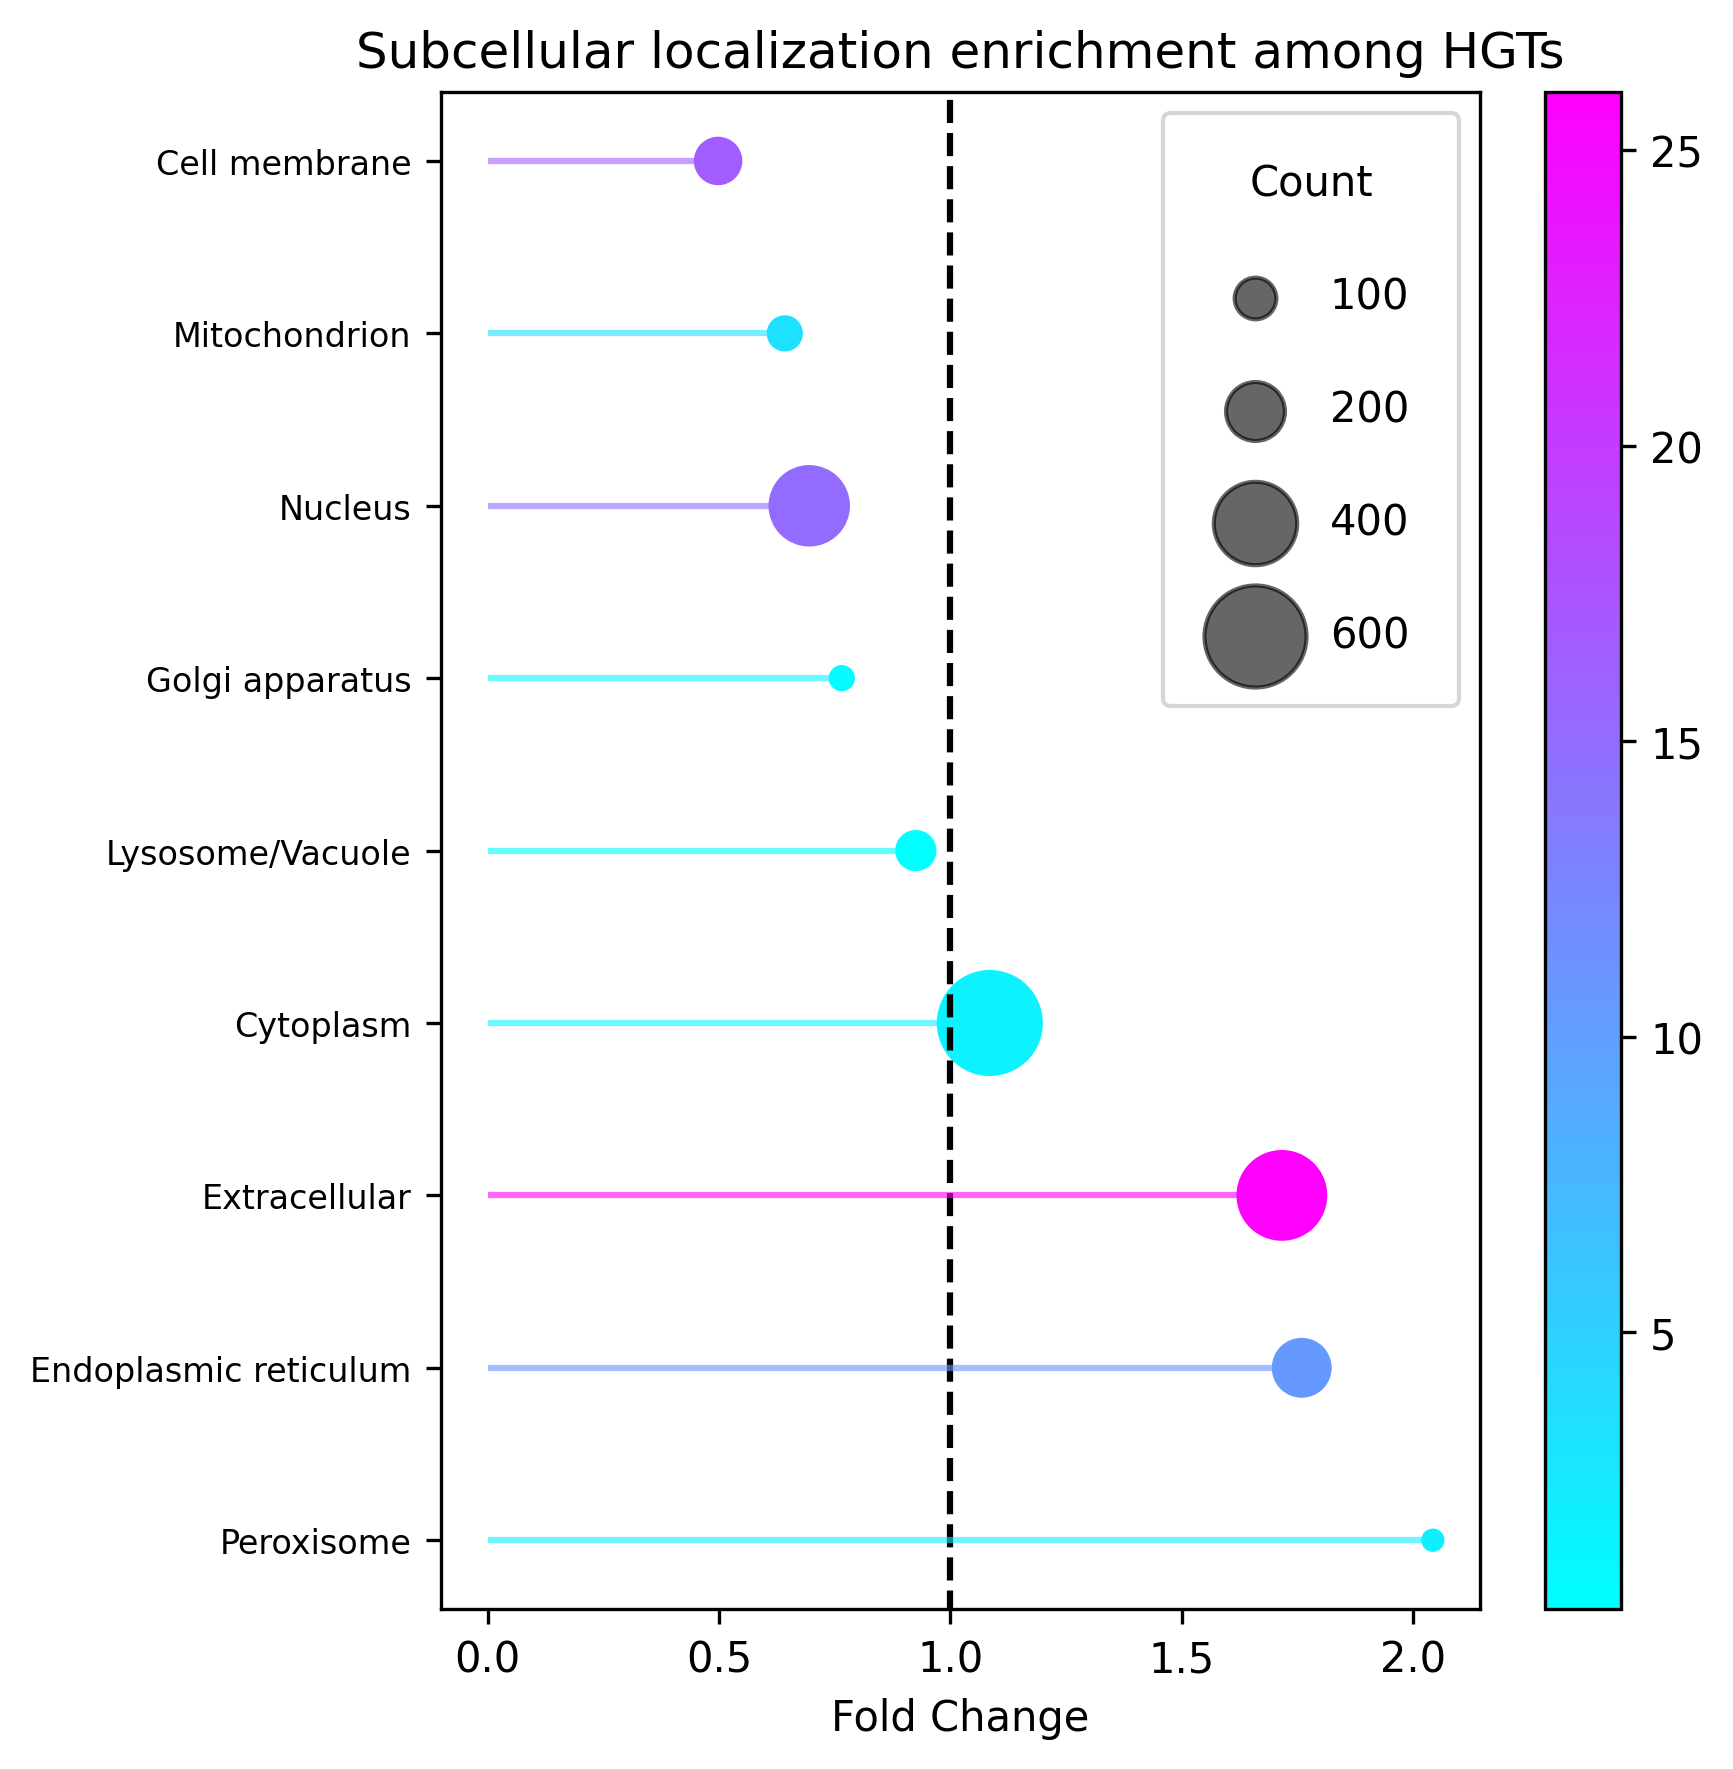

In [46]:

df=locdf.sort_values("FC",ascending=False)
plt.figure(figsize=(6, 6))  # Adjust the figure size
plt.vlines(1,-1,10,linestyle='dashed',color='black')

# Concatenate index and Name for y-axis labels
n = df.index

# Scatter plot

scatter = plt.scatter(df['FC'], n, s=df['HGT'], c=-np.log10(df['padj']), cmap='cool')

# Create dummy points for the legend
legend_sizes = [100,200,400,600]
for size in legend_sizes:
    plt.scatter([], [], s=size, label=str(size), color='black', alpha=0.6)

# Add legend
plt.legend(title='Count', scatterpoints=1, labelspacing=1.7, loc='upper right',borderpad=1.2)

# Colorbar
plt.colorbar(scatter)

# Add horizontal lines connecting each point to y-axis
for i, y_val in enumerate(n):
    plt.hlines(y_val, 0, df['FC'][i], colors=scatter.to_rgba(-np.log10(df['padj'])[i]), alpha=0.6)

# Labels and title
plt.xlabel('Fold Change')
plt.title('Subcellular localization enrichment among HGTs')

# Adjust y-axis font size
plt.yticks(fontsize=8)  # Set font size for y-axis labels

# Adjust layout to make all ticks visible
plt.tight_layout()
plt.savefig('figures/subcellular_localization_enrichment.svg',format='svg',bbox_inches='tight')


# Show plot
plt.show()

## GO enrichment analysis

In [23]:
%%bash
wget https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/014/529/535/GCF_014529535.2_BU_Bcop_v2.1/GCF_014529535.2-RS_2026_02_gene_ontology.gaf.gz
gunzip GCF_014529535.2-RS_2026_02_gene_ontology.gaf.gz
mv GCF_014529535.2-RS_2026_02_gene_ontology.gaf datasets

In [24]:
%%bash
wget https://purl.obolibrary.org/obo/go/go-basic.obo
mv go-basic.obo datasets

--2026-07-07 16:56:04--  https://purl.obolibrary.org/obo/go/go-basic.obo
Resolving purl.obolibrary.org (purl.obolibrary.org)... 104.18.37.59, 172.64.150.197, 2a06:98c1:3107::ac40:96c5, ...
Connecting to purl.obolibrary.org (purl.obolibrary.org)|104.18.37.59|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://current.geneontology.org/ontology/go-basic.obo [following]
--2026-07-07 16:56:04--  https://current.geneontology.org/ontology/go-basic.obo
Resolving current.geneontology.org (current.geneontology.org)... 172.64.145.49, 104.18.42.207, 2606:4700:4409::6812:2acf, ...
Connecting to current.geneontology.org (current.geneontology.org)|172.64.145.49|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 32215811 (31M) [text/obo]
Saving to: ‘go-basic.obo’

     0K .......... .......... .......... .......... ..........  0%  185M 0s
    50K .......... .......... .......... .......... ..........  0%  350M 0s
   100K .......... .......... .

In [2]:
dfriso=pd.read_csv("outputs/per_protein_diamond_data.tsv",sep="\t",index_col="accession")

In [3]:
#load a dictionary of go_term ids and attributes
f=open("datasets/go-basic.obo","r")
l=f.readlines()
go_dict={}
for x in l[50:]:
    if ":" in x:
        xl=x.split(": ")[1]
        xl=xl.strip()
        if 'id: ' in x:
          id=xl
          go_dict[id]={}
        key=x.split(": ")[0]
        key=key.strip()
        go_dict[id][key]=xl

In [4]:

godf=pd.read_csv("datasets/GCF_014529535.2-RS_2026_02_gene_ontology.gaf",sep="\t",index_col=0,comment="!",header=None)

In [10]:
for index, row in dfriso.iterrows():
    gene=row['gene']
    gi=godf[godf[2]==gene]
    if gi.shape[0]>0:
        di={"F":[],"P":[],"C":[]}
        for index2, row in gi.iterrows():
            c=row[8]
            go=row[4]
            name=go_dict[go]['name']
            s=f"{go}:{name}"
            l=di[c]
            l.append(s)
            di[c]=l
        for x in di:
            dfriso.loc[index,x]=str(di[x])
            


In [16]:
hgt_genes = set(dfriso.loc[dfriso.tree_HTG, "gene"])

bp_hgt_genes = set(
    godf.loc[
        (godf[8] == "P") &
        (godf[2].isin(hgt_genes)),
        2
    ]
)

n_bp_annotated_hgts = len(bp_hgt_genes)
n_bp_annotated_hgts 

584

In [21]:
18/584

0.030821917808219176

In [1]:
transposon_terms="GO:0006310|GO:0015074|GO:0006313|GO:0098039|GO:0098038|GO:0006317|GO:0006318|GO:0032197"

In [19]:
for x in transposon_terms.split("|"):
    try:
        print(x,go_dict[x]['name'])
    except:
        print(x)

GO:0006310 DNA recombination
GO:0015074 DNA integration
GO:0006313 DNA transposition
GO:0098039 replicative DNA transposition
GO:0098038 non-replicative DNA transposition
GO:0006317
GO:0006318
GO:0032197 retrotransposition


In [20]:
h[h.P.astype(str).str.contains(transposon_terms)].shape[0]

18

In [26]:
## percentage of htgs with at least one biological process term possibly associated with transposons
18/1099

0.01637852593266606

In [27]:
h=dfriso[dfriso.tree_HTG].loc[:,['description','F','P']]

h.description=[" ".join(x.replace(" [Bradysia coprophila]","").split(" ")[1:]) for x in h.description]
h['F']=[str(x).replace("[","").replace("]","").replace("'","").replace("nan","") for x in h['F']]
h['P']=[str(x).replace("[","").replace("]","").replace("'","").replace("nan","") for x in h['P']]
h.columns=['description','GO molecular function','GO biological process']
h.to_csv("outputs/hgt_go_terms.tsv",sep="\t")

In [28]:
##tabulate hgt gene count per go_term 
from collections import Counter
hgts=set(dfriso[dfriso.tree_HTG].gene)
hgtgo=list(godf[godf[2].isin(hgts)][4])
m=set(Counter(hgtgo))
hgtdf = pd.DataFrame(index=list(m))
for index, row in hgtdf.iterrows():
  hgtdf.loc[index,"Name"]=go_dict[index]['name']
  hgtdf.loc[index,"Component"]=go_dict[index]['namespace']

In [29]:
for index, row in hgtdf.iterrows():
  total_genes=list(set(godf[godf[4]==index][2]))
  hgt_genes=list(dfriso[(dfriso.tree_HTG)&(dfriso.gene.isin(total_genes))].gene)
  desc=str(list(dfriso[dfriso.gene.isin(hgt_genes)].description))
  hgtdf.loc[index,"genes"]=str(hgt_genes)
  hgtdf.loc[index,"genes_desc"]=desc
  hgtdf.loc[index,"Total_count"]=len(total_genes)
  hgtdf.loc[index,"HGT_count"]=len(hgt_genes)


In [30]:
all_hgt_genes=set(dfriso[dfriso.tree_HTG].gene)
len(all_hgt_genes)

1517

In [34]:
##molecular function enrichment
##number of hgts with any go term 
n_hgts_with_go=len(set(godf[(godf[8]=='F')&(godf[2].isin(all_hgt_genes))][2]))
##number of non-hgts with any go term
n_non_hgts_with_go=len(set(godf[(godf[8]=='F')&~(godf[2].isin(all_hgt_genes))][2]))
mfdf=hgtdf[hgtdf.Component=="molecular_function"]
for index, row in mfdf.iterrows():
  ##number of hgts with specific go term, number hgts without term
  go_counts = [row.HGT_count, n_hgts_with_go-row.HGT_count]  # Counts for the GO term of interest
  #number of non hgts with specific go term, number non hgts  without term
  background_counts = [row.Total_count-row.HGT_count,n_non_hgts_with_go-(row.Total_count-row.HGT_count)]  # Counts for the background set (total non hgt, total 
  mfdf.loc[index,["FC","p_value"]]=go_enrichment_analysis(go_counts, background_counts, alternative='greater')
mfdf['padj']=statsmodels.stats.multitest.multipletests(mfdf["p_value"],method='fdr_bh')[1]

mfdf.index.name='GO term'
mfdf=mfdf.sort_values('HGT_count',ascending=False)
mfdf.to_csv('outputs/molecular_function_enrichment.tsv',sep='\t')

/tmp/ipykernel_3135052/1571099779.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mfdf['padj']=statsmodels.stats.multitest.multipletests(mfdf["p_value"],method='fdr_bh')[1]


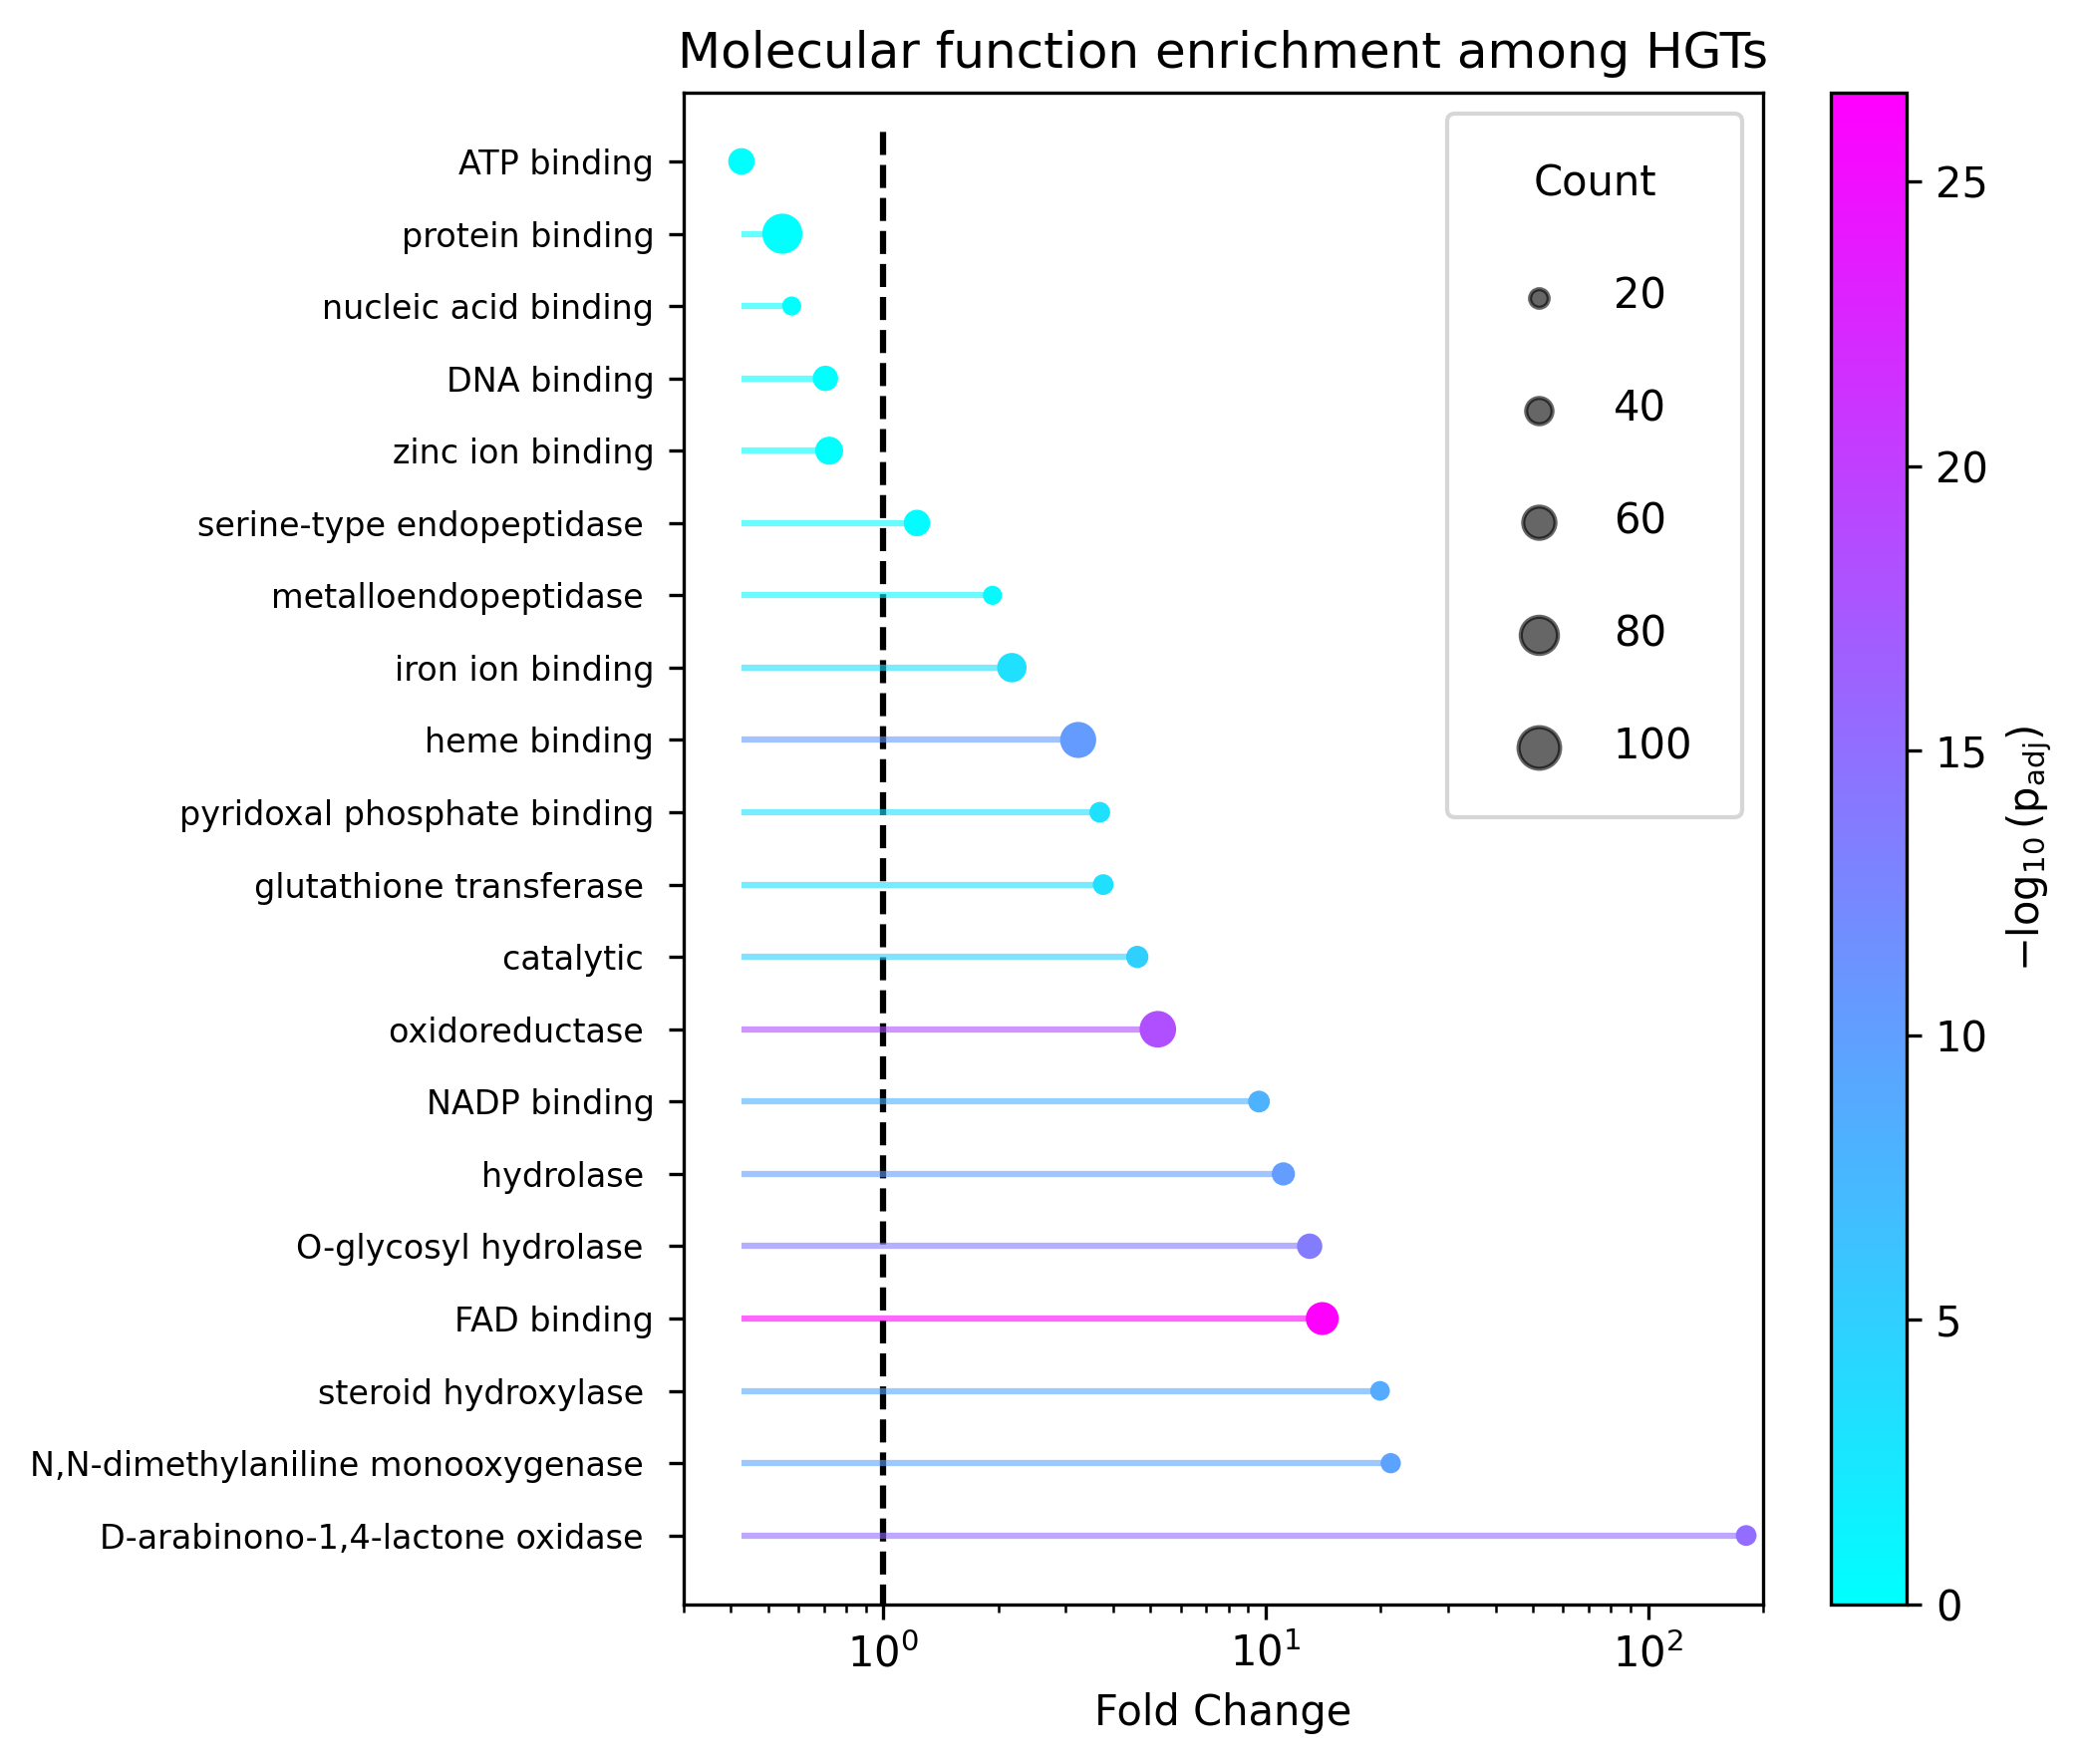

In [65]:
dfi = mfdf.sort_values("HGT_count", ascending=False).iloc[0:24, :].sort_values('FC', ascending=False)
dfi = dfi[~((dfi.Name.str.contains("paired donors") | dfi.Name.str.contains("flavin")) | dfi.Name.str.contains('CH-OH'))]
dfi.Name = dfi.Name.replace(
    'hydrolase activity, hydrolyzing O-glycosyl compounds',
    'O-glycosyl hydrolase activity'
)
dfi.Name = [x.replace('activity', '') for x in dfi.Name]

plt.figure(figsize=(7, 6))
plt.vlines(1,-1,19.5,linestyle='dashed',color='black')
# Concatenate index and Name for y-axis labels
n = [y for x, y in zip(dfi.index, dfi.Name)]

# Scatter plot
scatter = plt.scatter(
    dfi['FC'],
    n,
    s=dfi['HGT_count'],
    c=-np.log10(dfi['padj']),
    cmap='cool'
)

# Make x-axis log scale
plt.xscale('log')

# Create dummy points for the legend
legend_sizes = [20, 40, 60, 80, 100]
for size in legend_sizes:
    plt.scatter([], [], s=size, label=str(size), color='black', alpha=0.6)

plt.legend(
    title='Count',
    scatterpoints=1,
    labelspacing=1.7,
    loc='upper right',
    borderpad=1.2
)

plt.colorbar(scatter, label=r'$-\log_{10}(\text{p}_{\text{adj}})$')

# Add horizontal lines connecting each point to log-scale baseline
xmin = dfi['FC'].min()

for i, y_val in enumerate(n):
    plt.hlines(
        y_val,
        xmin,
        dfi['FC'].iloc[i],
        colors=scatter.to_rgba(-np.log10(dfi['padj']).iloc[i]),
        alpha=0.6
    )

plt.xlabel('Fold Change')
plt.title('Molecular function enrichment among HGTs')
plt.yticks(fontsize=8)
plt.xlim(.3,200)
plt.tight_layout()


plt.savefig(
    'figures/molecular_function_enrichment.svg',
    format='svg',
    bbox_inches='tight'
)

plt.show()

In [66]:
##number of hgts with any go term 
n_hgts_with_go=len(set(godf[(godf[8]=='P')&(godf[2].isin(all_hgt_genes))][2]))
##number of non-hgts with any go term
n_non_hgts_with_go=len(set(godf[(godf[8]=='P')&~(godf[2].isin(all_hgt_genes))][2]))
bpdf=hgtdf[hgtdf.Component=="biological_process"]
for index, row in bpdf.iterrows():
  ##number of hgts with specific go term, number hgts without term
  go_counts = [row.HGT_count, n_hgts_with_go-row.HGT_count]  # Counts for the GO term of interest
  #number of non hgts with specific go term, number non hgts  without term
  background_counts = [row.Total_count-row.HGT_count,n_non_hgts_with_go-(row.Total_count-row.HGT_count)]  # Counts for the background set (total non hgt, total 
  bpdf.loc[index,["FC","p_value"]]=go_enrichment_analysis(go_counts, background_counts, alternative='greater')
bpdf['padj']=statsmodels.stats.multitest.multipletests(bpdf["p_value"],method='fdr_bh')[1]

bpdf.index.name='GO term'
bpdf=bpdf.sort_values('HGT_count',ascending=False)
bpdf.to_csv('outputs/biological_process_enrichment.tsv',sep='\t')

/tmp/ipykernel_3135052/3309384651.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  bpdf['padj']=statsmodels.stats.multitest.multipletests(bpdf["p_value"],method='fdr_bh')[1]


/tmp/ipykernel_3135052/2571834776.py:31: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.hlines(y_val, 0, dfi['FC'][i], colors=scatter.to_rgba(-np.log10(dfi['padj'])[i]), alpha=0.6)


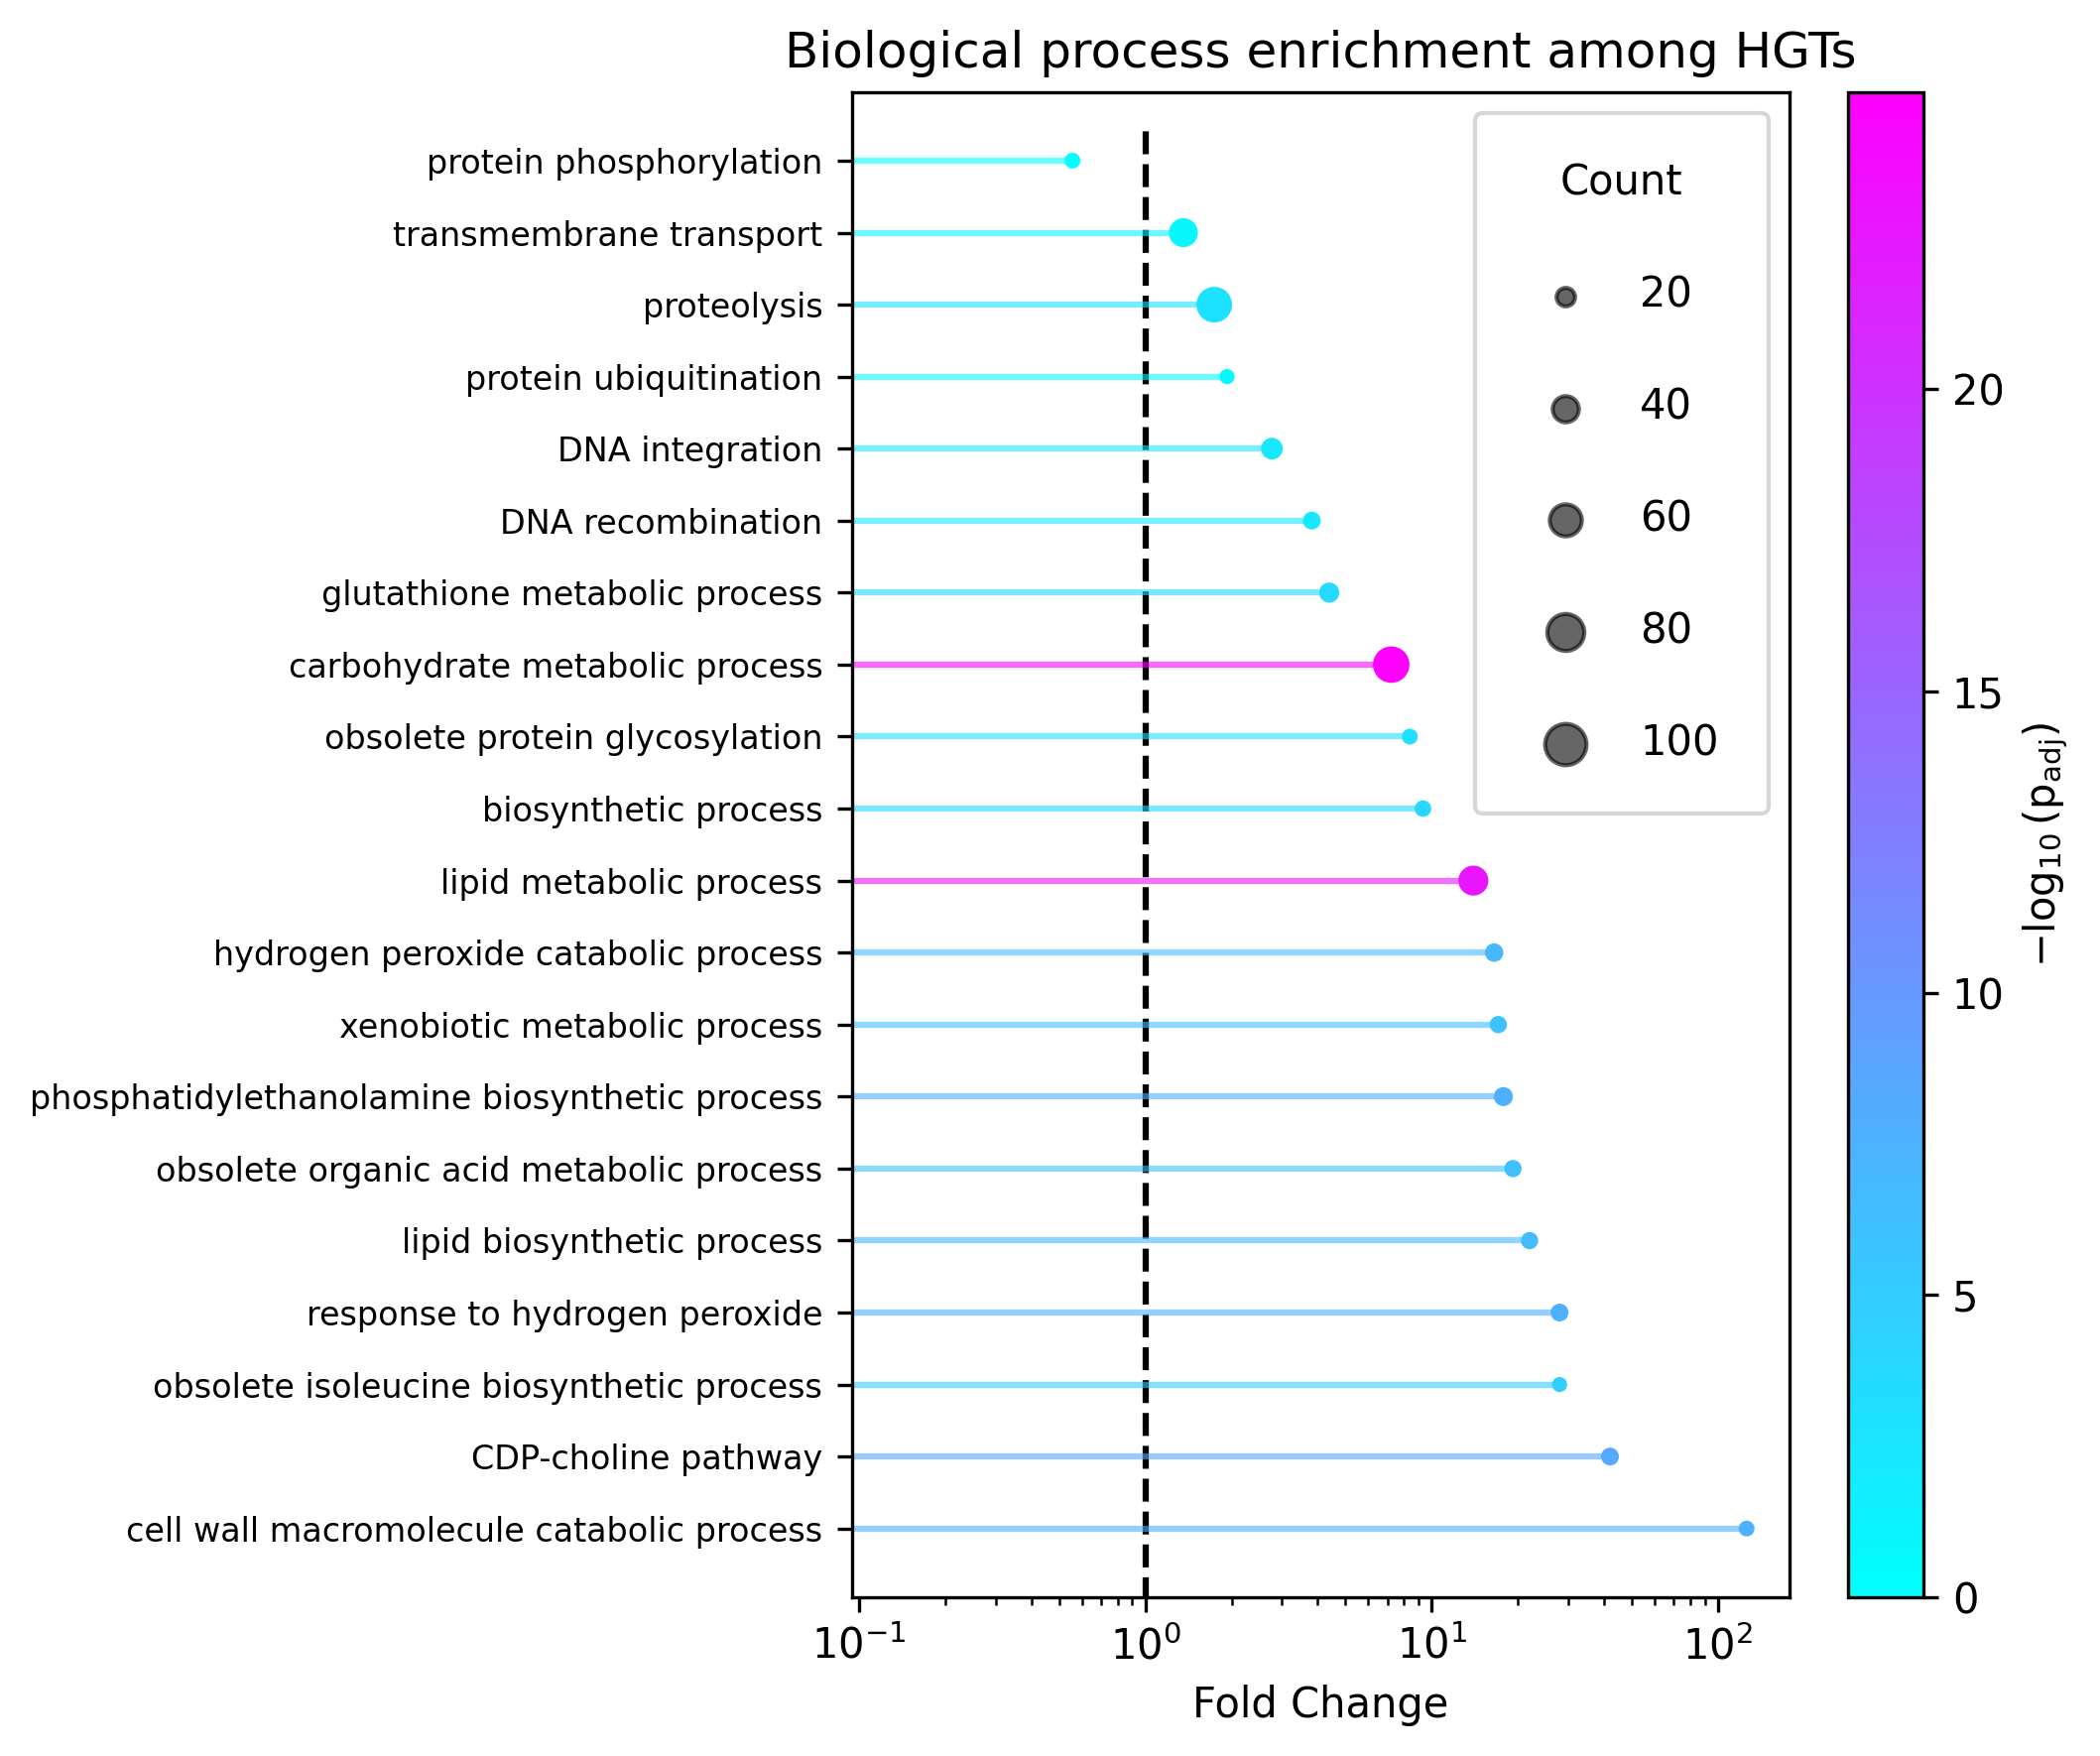

In [69]:
dfi=bpdf.sort_values("HGT_count",ascending=False).iloc[0:20,:].sort_values('FC',ascending=False)
dfi=dfi[~(dfi.Name.str.contains("paired donors")|dfi.Name.str.contains("flavin"))]
dfi.Name=dfi.Name.replace('hydrolase activity, hydrolyzing O-glycosyl compounds','O-glycosyl hydrolase activity')
dfi.Name=[x.replace('activity','') for x in dfi.Name]


plt.figure(figsize=(7, 6)) # Adjust the figure size
plt.vlines(1,-1,19.5,linestyle='dashed',color='black')

# Concatenate index and Name for y-axis labels
n = [y for x,y in zip (dfi.index,dfi.Name)]

# Scatter plot
ymin,ymax=plt.ylim()

scatter = plt.scatter(dfi['FC'], n, s=dfi['HGT_count'], c=-np.log10(dfi['padj']), cmap='cool')

# Create dummy points for the legend
legend_sizes = [20,40,60,80,100]
for size in legend_sizes:
    plt.scatter([], [], s=size, label=str(size), color='black', alpha=0.6)

# Add legend
plt.legend(title='Count', scatterpoints=1, labelspacing=1.7, loc='upper right',borderpad=1.2)
plt.xscale('log')
# Colorbar
plt.colorbar(scatter, label=r'$-\log_{10}(\text{p}_{\text{adj}})$')

# Add horizontal lines connecting each point to y-axis
for i, y_val in enumerate(n):
    plt.hlines(y_val, 0, dfi['FC'][i], colors=scatter.to_rgba(-np.log10(dfi['padj'])[i]), alpha=0.6)

# Labels and title
plt.xlabel('Fold Change')
plt.title('Biological process enrichment among HGTs')

# Adjust y-axis font size
plt.yticks(fontsize=8)  # Set font size for y-axis labels

# Adjust layout to make all ticks visible
plt.tight_layout()
plt.savefig('figures/biological_process_enrichment.svg',format='svg',bbox_inches='tight')


# Show plot
plt.show()

## Comparison to carbohydrate-active enzyme data and salivary proteomics from Monesi et al.  DOI: 10.1016/j.isci.2023.106449


In [4]:
!cp -r ../Bradysia_coprophila/Pseudolycoriella_hygida_data/ ./datasets/

In [ ]:
import pandas as pd

In [9]:
manual=pd.read_csv("outputs/SI_inspection_bradysia_6_23_2026.tsv",sep="\t",index_col=0)

In [10]:
gene=pd.read_csv("ncbi_dataset/data/GCA_029228625.1/genomic.gff",sep="\t",comment="#",header=None)
gene=gene[gene[2]=='CDS']
gmap={x.split(";")[0].replace("ID=cds-",""):x.split("locus_tag=")[1].split(";")[0] for x in gene[8]}
rgmap={x.split("locus_tag=")[1].split(";")[0]:x.split(";")[0].replace("ID=cds-","") for x in gene[8]}

In [11]:
##P. hygida orthologs to b. coprophila hgts
import ast
phyg_prots=[]
for index, row in manual[~manual.annotation.isin(['Reject','Other direction'])].iterrows():
    seqs=[x.strip() for x in row.all_seqs.split(",")]
    phyg_prots.extend([x for x in seqs if 'KAJ' in x])

In [12]:
import pandas as pd
#### percent of p.hygida proteome (Table S10.)
prot=pd.read_csv("datasets/Pseudolycoriella_hygida_data/phyg_proteome.tsv",sep="\t",index_col=0)
prot['prot']=[rgmap[x.split("-")[0]] for x in prot.index]
len(set(prot.prot)&set(phyg_prots)),prot.shape[0],len(set(prot.prot)&set(phyg_prots))/prot.shape[0]

(126, 1149, 0.10966057441253264)

In [10]:
prot=prot[prot.prot.isin(set(phyg_prots))]
for index, row in prot.iterrows():
  
    os=manual[manual.all_seqs.str.contains(row['prot'])].cluster_seqs.values
    orthologs=set()
    for x in os:
        orthologs=orthologs|set(ast.literal_eval(x))
    prot.loc[index,'B.copro_orthologs']=str(orthologs).replace("{","").replace("}","").replace("'","")
prot=prot.loc[:,['Name','prot','B.copro_orthologs','Unique peptides']]
prot.to_csv("outputs/p_hygida_proteome.tsv",sep='\t')

In [4]:
dfriso=pd.read_csv("outputs/per_protein_diamond_data.tsv",sep="\t",index_col="accession")
hgts=set(dfriso[dfriso.tree_HTG].gene)
len(hgts)

1517

In [34]:
%%bash
wget https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/014/529/535/GCF_014529535.1_BU_Bcop_v1/GCF_014529535.1_BU_Bcop_v1_protein.faa.gz
gunzip GCF_014529535.1_BU_Bcop_v1_protein.faa.gz
mv GCF_014529535.1_BU_Bcop_v1_protein.faa datasets/

--2026-07-07 18:45:05--  https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/014/529/535/GCF_014529535.1_BU_Bcop_v1/GCF_014529535.1_BU_Bcop_v1_protein.faa.gz
Resolving ftp.ncbi.nlm.nih.gov... 130.14.250.13, 130.14.250.31, 2607:f220:41e:250::7, ...
Connecting to ftp.ncbi.nlm.nih.gov|130.14.250.13|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 6280054 (6.0M) [application/x-gzip]
Saving to: ‘GCF_014529535.1_BU_Bcop_v1_protein.faa.gz’

     0K .......... .......... .......... .......... ..........  0% 1.20M 5s
    50K .......... .......... .......... .......... ..........  1% 3.67M 3s
   100K .......... .......... .......... .......... ..........  2% 3.91M 3s
   150K .......... .......... .......... .......... ..........  3% 63.3M 2s
   200K .......... .......... .......... .......... ..........  4% 85.6M 2s
   250K .......... .......... .......... .......... ..........  4%  132M 1s
   300K .......... .......... .......... .......... ..........  5% 3.98M 1s
   350K ....

In [90]:
%%bash
singularity exec /cvmfs/singularity.galaxyproject.org/d/i/diamond:2.2.0--he361c42_0 diamond blastp --query "datasets/GCF_014529535.1_BU_Bcop_v1_protein.faa"  --db "ncbi_dataset/data/GCF_014529535.2/protein.faa" --out "outputs/new_vs_old.tsv" --outfmt 6 qseqid sseqid stitle pident length mismatch gapopen qstart qend sstart send evalue bitscore qcovhsp --threads 110 --evalue .01 --very-sensitive -k5

diamond v2.2.0.180 (C) Max Planck Society for the Advancement of Science, Benjamin J. Buchfink, University of Tuebingen
Documentation, support and updates available at http://www.diamondsearch.org
Please cite: http://dx.doi.org/10.1038/s41592-021-01101-x Nature Methods (2021)

#CPU threads: 110
Scoring parameters: (Matrix=BLOSUM62 Lambda=0.267 K=0.041 Penalties=11/1)
Temporary directory: outputs
#Target sequences to report alignments for: 5
Opening the database...  [0.038s]
FASTA file size: 20576974 bytes
Loaded 20576974 bytes from disk at 1370.66 MB/s
Database: ncbi_dataset/data/GCF_014529535.2/protein.faa (type: FASTA file, sequences: 27667, letters: 18177294)
Block size = 400000000
Opening the input file...  [0.009s]
Opening the output file...  [0.007s]
Loading query sequences...  [0.009s]
Loaded 21385813 bytes from disk at 2141.89 MB/s
Masking queries...  [0.176s]
Algorithm: Double-indexed
Building query histograms...  [0.032s]
Seeking in database...  [0s]
Loading reference sequenc

## B. coprophila cazyme mapping

In [1]:
from Bio import SeqIO

In [2]:
input_file = open(f"datasets/GCF_014529535.1_BU_Bcop_v1_protein.faa")
old_fasta = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))

input_file = open(f"ncbi_dataset/data/GCF_014529535.2/protein.faa")
new_fasta = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))
import pandas as pd
new_old=pd.read_csv("outputs/new_vs_old.tsv",sep="\t",header=None)

new_old.columns="qseqid sseqid stitle pident length mismatch gapopen qstart qend sstart send evalue bitscore qcovhsp".split(" ")
new_old=new_old[(new_old['pident']>95)&(new_old['qcovhsp']>85)]
new_old_best = new_old.loc[new_old.groupby("qseqid")["evalue"].idxmin()].reset_index(drop=True)
gff=pd.read_csv("ncbi_dataset/data/GCF_014529535.2/genomic.gff",sep="\t",comment="#",header=None)
def get_gene(x):
    return gff[gff[8].str.contains(x)].iloc[0,8].split(";gene=")[1].split(";")[0]
def old_prot_to_new_prot(x):
    if x in new_fasta.keys():
        return dfriso[dfriso.gene==get_gene(x)].index[0]
    elif x in set(new_old_best.qseqid):
        x= new_old_best[new_old_best.qseqid==x].sseqid.values[0]
        return dfriso[dfriso.gene==get_gene(x)].index[0]
    else:
        return "no_map"


In [5]:
## load bcopro predicted cazymes from Monesi table S9
cazy=pd.read_csv('datasets/Pseudolycoriella_hygida_data/bcopro_cazy.tsv',sep='\t',index_col=0)
print(cazy.shape[0])
cazy['new_prot']=[old_prot_to_new_prot(x) for x in cazy.index]
print(cazy.shape[0])

371
371


In [6]:
cazy=cazy[cazy['CAZy family']!=' - ']
cazy.shape[0]

270

In [7]:
cazy=cazy[cazy['new_prot']!='no_map']
cazy.shape[0]

258

In [8]:
hgt_cazy=cazy[cazy.new_prot.isin(dfriso[dfriso.tree_HTG].index)]
hgt_cazy.shape[0]


89

In [61]:

hgt_cazy.to_csv("outputs/predicted_cazymes.csv")

In [106]:

cazy[cazy['CAZy family']!=' - '].shape[0]

255

In [ ]:
##load experimentally-validated p.lycoriella HGTs from monesi et al

In [11]:
gene=pd.read_csv("ncbi_dataset/data/GCA_029228625.1/genomic.gff",sep="\t",comment="#",header=None)
gene=gene[gene[2]=='CDS']
gmap={x.split(";")[0].replace("ID=cds-",""):x.split("locus_tag=")[1].split(";")[0] for x in gene[8]}
rgmap={x.split("locus_tag=")[1].split(";")[0]:x.split(";")[0].replace("ID=cds-","") for x in gene[8]}

In [16]:
phyg_gene={gmap[x] for x in phyg_prots}

In [20]:
mcon=pd.read_csv('datasets/Pseudolycoriella_hygida_data/monesi_confirmed_cazys.tsv',sep='\t')
print(mcon.shape[0])
mcon['Protein']=[x.split("-")[0] for x in mcon.Protein]
dfr=mcon[mcon['Protein'].isin(phyg_gene)]

18


In [21]:
dfr['Protein']=[rgmap[x] for x in dfr.Protein]
for index, row in dfr.iterrows():
  
    os=manual[manual.all_seqs.str.contains(row['Protein'])].cluster_seqs
    orthologs=set()
    for x in os:
        orthologs=orthologs|set(ast.literal_eval(x))
    dfr.loc[index,'B.copro_orthologs']=str(orthologs).replace("{","").replace("}","").replace("'","")

/n/home11/rkapoor/.conda/envs/jupyter_3.6/lib/python3.6/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  """Entry point for launching an IPython kernel.
/n/home11/rkapoor/.conda/envs/jupyter_3.6/lib/python3.6/site-packages/pandas/core/indexing.py:1596: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self.obj[key] = _infer_fill_value(value)
/n/home11/rkapoor/.conda/envs/jupyter_3.6/lib/python3.6/site-packages/pandas/core/indexing.py:1763: SettingWithCopyWarning: 
A value is 

In [22]:
dfr.columns=['P.hygida_protein', 'Annotation', 'EC Number', 'CAZy family', 'Substrate',
       'Activity', 'B.copro_orthologs']
dfr=dfr.loc[:,['P.hygida_protein', 'B.copro_orthologs', 'Annotation', 'EC Number', 'CAZy family', 'Substrate', "Activity"]]
dfr.to_csv("outputs/confirmed_cazymes.tsv",sep="\t")

In [23]:
dfr.shape[0]

12